# 夸父金融 D1：编译与制备／测量诊断

这是五类金融案例的**独立诊断附件**，不是第六个金融模型。所有图表读取已完成的真实任务收据。
重跑本 notebook **不会访问网络、读取密钥或提交任务**。原有 9 项金融实验不覆盖、不修正。

问题：金融电路已在 Dongling 执行，但为什么与理想结果偏差明显？先检查返回的编译电路，
再用最简单的 3／4 比特全零、全一态观测制备和测量的综合偏差。总额度已使用 **13/20**，保留 7 项。
不能把“任务 DONE”写成“金融精度通过”。

In [1]:
import hashlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
while not (root / "quantumbridge/finance").is_dir() and root != root.parent:
    root = root.parent
base = root / "output/finance-hardware/diagnostics"
load = lambda name: json.loads((base / name).read_text())
integrity = load("original_evidence_integrity.json")
assert integrity["unchanged"]
assert all(hashlib.sha256((root / name).read_bytes()).hexdigest() == value
           for name, value in integrity["before"].items())
print("原始证据 SHA-256 复核通过，文件数:", len(integrity["before"]))
audits = load("compiled_circuit_manifest.json")
probes = load("diagnostic_compiled_manifest.json")
metrics = load("zero_one_metrics.json")
decisions = load("diagnosis_decisions.json")
assert decisions["total_tasks"] == 13 and decisions["remaining_tasks"] == 7


原始证据 SHA-256 复核通过，文件数: 26


## 1. 编译前后：比较测量输出，不比较不同物理编号的裸态向量

将返回的稀疏物理寄存器压缩为实际活动量子位，再使用 QuantumBridge 原生执行器。
QASM2 与独立的安全 QLISP 字面量解析分别执行 U、CZ、测量；没有调用 Qiskit／PennyLane 执行器。
经典输出按 `c0,c1,...` 排列后计算总变差距离 $TVD=\frac12\sum_x|p(x)-q(x)|$。
这只验证零输入下理想分布，**不是**完整酉矩阵、脉冲时序或硬件校准的证明。


In [2]:
rows = []
for name, audit in audits.items():
    rows.append({"experiment": name, "task_id": audit["task_id"],
                 "compiled_TVD": audit["compiled_vs_submitted_tvd"],
                 "QLISP_TVD": audit["qlisp_vs_compiled_tvd"],
                 "c_to_physical": audit["native_compiled"]["physical_measurement_map"],
                 "physical_set": sorted(audit["native_compiled"]["active_physical_qubits"])})
display(pd.DataFrame(rows))
assert max(row["compiled_TVD"] for row in rows) < 1e-8
assert all(row["QLISP_TVD"] == 0 for row in rows)
print("原始任务的编译电路理想分布与提交电路几乎相同，不能解释已观察到的巨大真机偏差。")


,experiment,task_id,compiled_TVD,QLISP_TVD,c_to_physical,physical_set
0,calibration/bit-order,2610231235264038840,1.874700e-33,0.0,"{'0': 11, '1': 4}","[4, 11]"
1,allocation/qaoa,2610231235383826369,6.811068e-11,0.0,"{'0': 10, '1': 3, '2': 4, '3': 11}","[3, 4, 10, 11]"
2,risk/base,2610231235440801552,6.757590e-11,0.0,"{'0': 10, '1': 3, '2': 4}","[3, 4, 10]"
3,risk/stress,2610231235484838251,4.216744e-11,0.0,"{'0': 10, '1': 3, '2': 4}","[3, 4, 10]"
4,derivatives/risk_neutral_paths,2610231235566974565,5.351759e-11,0.0,"{'0': 11, '1': 4, '2': 5}","[4, 5, 11]"
5,constraints/qaoa,2610231236018836200,1.229930e-10,0.0,"{'0': 10, '1': 3, '2': 4, '3': 11}","[3, 4, 10, 11]"
6,correlation/positive_correlation,2610231236118773106,8.126112e-11,0.0,"{'0': 10, '1': 3, '2': 11, '3': 4}","[3, 4, 10, 11]"
7,correlation/negative_correlation,2610231236189351427,6.149433e-11,0.0,"{'0': 10, '1': 3, '2': 11, '3': 4}","[3, 4, 10, 11]"
8,correlation/time_sampling,2610231236333069511,2.220446e-16,0.0,"{'0': 11, '1': 4, '2': 5}","[4, 5, 11]"


原始任务的编译电路理想分布与提交电路几乎相同，不能解释已观察到的巨大真机偏差。


## 2. 中间证据：实际 QASM、任务 ID、编译选项与缺失字段

全零态只测量，不加制备门；全一态对每位施加 X 后测量。每项 1024 shots。
下方电路来自持久收据，不重新生成替代原始证据。
`compile=True` 及返回 QASM 可读，但编译器版本、校准 ID、raw counts 字符串位序未提供；不能猜测。


In [3]:
ledger = load("diagnostic_task_ledger.json")
for key, saved in ledger["jobs"].items():
    print(key, saved["job"]["job_id"], saved["job"]["status"], "shots=", saved["job"]["shots"])
    print(saved["artifact"]["openqasm"])
    print("SHA-256:", saved["artifact"]["sha256"])
    assert saved["job"]["shots"] == 1024 and saved["job"]["status"] == "DONE"
    assert sum(saved["raw_counts"].values()) == 1024
display(pd.DataFrame([{ "probe": key, "physical_map": value["native_compiled"]["physical_measurement_map"],
                       "compiled_TVD": value["compiled_vs_submitted_tvd"],
                       "calibration_id": value["fields"]["calibration_id"]["status"]}
                      for key, value in probes.items()]))


diagnostic/3q-zero 2610231309374778530 DONE shots= 1024
OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];
creg c[3];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];

SHA-256: f3bbea08f9778d7473eb1bc1ef0501e9be6a2cb77eef1f8d9e1f241645ed2bb0
diagnostic/3q-one 2610231309431738918 DONE shots= 1024
OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];
creg c[3];
x q[0];
x q[1];
x q[2];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];

SHA-256: a0144d8d864deb1a242be1712c51a6333ac1a5abd3ba98719bd5ad0dbbd86d0a
diagnostic/4q-zero 2610231309495020213 DONE shots= 1024
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];
measure q[3] -> c[3];

SHA-256: 22c3264d08953f3aade8aa89d4a9e8e27ecb50b997e834534e8e335517b28adc
diagnostic/4q-one 2610231310018516967 DONE shots= 1024
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
x q[0];
x q[1];
x q[2];
x q[3];
measure q[0] -> c[0];
measure q[1] -> c[1];
m

,probe,physical_map,compiled_TVD,calibration_id
0,diagnostic/3q-zero,"{'0': 11, '1': 4, '2': 5}",0.000000e+00,ABSENT
1,diagnostic/3q-one,"{'0': 11, '1': 4, '2': 5}",5.624099e-33,ABSENT
2,diagnostic/4q-zero,"{'0': 10, '1': 11, '2': 4, '3': 5}",0.000000e+00,ABSENT
3,diagnostic/4q-one,"{'0': 10, '1': 11, '2': 4, '3': 5}",7.498799e-33,ABSENT


## 3. 最终观测：目标态命中率与 Wilson 95% 区间

目标全零／全一态是确定性的，任何其他结果都是相对目标的表观错误。
Wilson 区间描述假设独立同分布时的抽样不确定性，不覆盖漂移和系统性硬件误差。
全一态还包含 X 制备误差，不能把下表称作“纯读出保真度”。


,probe,task_id,shots,success,Wilson95,multi_bit_error
0,diagnostic/3q-zero,2610231309374778530,1024,0.838867,"[0.8150888124545721, 0.8601125953542441]",0.014648
1,diagnostic/3q-one,2610231309431738918,1024,0.708984,"[0.6804232524829628, 0.7359833794221862]",0.028320
2,diagnostic/4q-zero,2610231309495020213,1024,0.809570,"[0.7843816756161099, 0.832444970710676]",0.021484
3,diagnostic/4q-one,2610231310018516967,1024,0.703125,"[0.6744244203796179, 0.7303072592291249]",0.036133


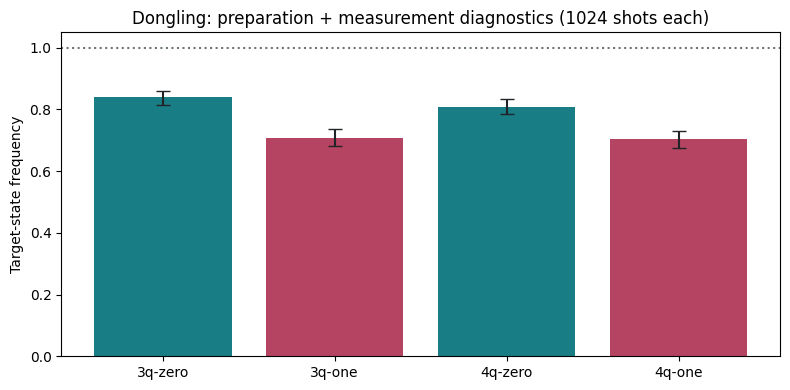

In [4]:
table = pd.DataFrame([{"probe": key, "task_id": value["task_id"], "shots": value["shots"],
                       "success": value["success_probability"], "Wilson95": value["success_wilson_95"],
                       "multi_bit_error": value["multiple_bit_error_probability"]}
                      for key, value in metrics.items()])
display(table)
names = [key.split("/")[1] for key in metrics]
values = np.array([value["success_probability"] for value in metrics.values()])
bounds = np.array([value["success_wilson_95"] for value in metrics.values()])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(names, values, color=["#197d86", "#b44462", "#197d86", "#b44462"])
ax.errorbar(names, values, yerr=[values - bounds[:, 0], bounds[:, 1] - values], fmt="none", color="#202427", capsize=5)
ax.axhline(1, color="#6d7477", linestyle=":")
ax.set(ylim=(0, 1.05), ylabel="Target-state frequency", title="Dongling: preparation + measurement diagnostics (1024 shots each)")
fig.tight_layout()
plt.show()


## 4. 原始分布、逐位置错误与相关错误

由于 raw counts 字符串的位序尚未独立确认，这里使用**字符串从左到右的位置**，不伪称 c0 或某一物理位。
两位同时错误的经验协方差为 $E[e_i e_j]-E[e_i]E[e_j]$；不能先假设误差独立，再反推出所谓真实读出矩阵。


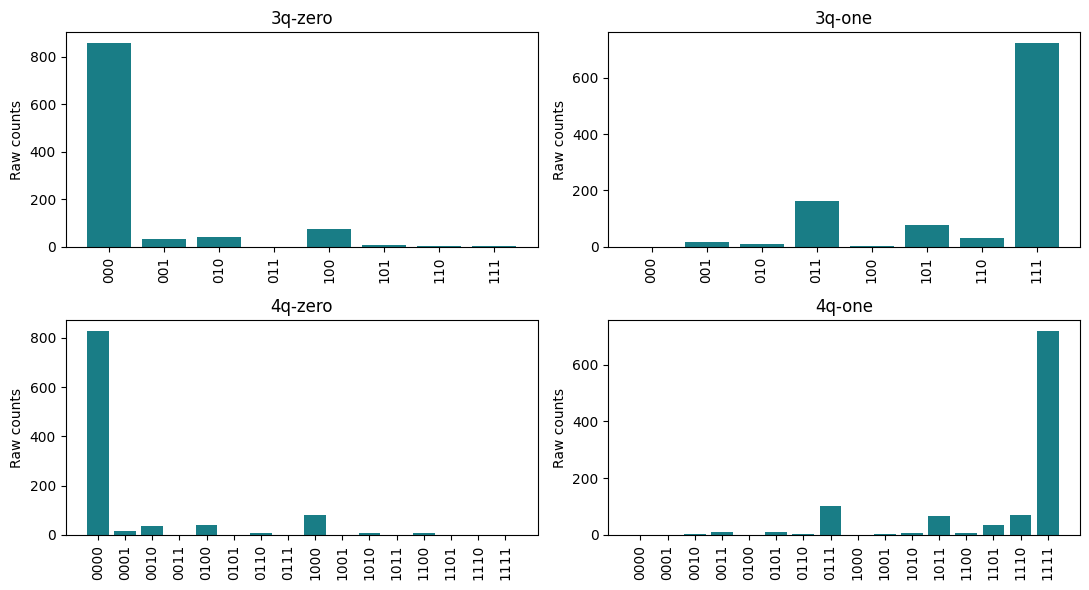

,probe,position,probability,wilson_95
0,diagnostic/3q-zero,0,0.088867,"[0.07294013925491286, 0.10786737461392984]"
1,diagnostic/3q-zero,1,0.046875,"[0.035535985542678575, 0.061601036868587464]"
2,diagnostic/3q-zero,2,0.041992,"[0.03132325446943114, 0.056084641028163185]"
3,diagnostic/3q-one,0,0.182617,"[0.16015422247521732, 0.20745252813612208]"
4,diagnostic/3q-one,1,0.094727,"[0.07827489001348567, 0.11420757615176305]"
5,diagnostic/3q-one,2,0.041992,"[0.03132325446943114, 0.056084641028163185]"
6,diagnostic/4q-zero,0,0.094727,"[0.07827489001348567, 0.11420757615176305]"
7,diagnostic/4q-zero,1,0.051758,"[0.039786304459362334, 0.0670798448655754]"
8,diagnostic/4q-zero,2,0.050781,"[0.038933483946073155, 0.06598683999613024]"
9,diagnostic/4q-zero,3,0.016602,"[0.01039069464635897, 0.02642574090014249]"


,probe,raw_label_positions,joint_error_probability,joint_error_wilson_95,error_covariance
0,diagnostic/3q-zero,"[0, 1]",0.005859,"[0.002688088875029841, 0.012724267461393879]",0.001694
1,diagnostic/3q-zero,"[0, 2]",0.010742,"[0.006008712294577325, 0.0191327709555181]",0.007010
2,diagnostic/3q-zero,"[1, 2]",0.001953,"[0.0005357808273541002, 0.007093273978132256]",-0.000015
3,diagnostic/3q-one,"[0, 1]",0.015625,"[0.00964032654076094, 0.025230283623006187]",-0.001674
4,diagnostic/3q-one,"[0, 2]",0.009766,"[0.005313035304722444, 0.017882622562638638]",0.002097
5,diagnostic/3q-one,"[1, 2]",0.002930,"[0.0009968475014902937, 0.008578032686730403]",-0.001048
6,diagnostic/4q-zero,"[0, 1]",0.006836,"[0.003315209271509724, 0.014042972447648336]",0.001933
7,diagnostic/4q-zero,"[0, 2]",0.007812,"[0.003963934516816084, 0.015340072585076314]",0.003002
8,diagnostic/4q-zero,"[0, 3]",0.001953,"[0.0005357808273541002, 0.007093273978132256]",0.000381
9,diagnostic/4q-zero,"[1, 2]",0.006836,"[0.003315209271509724, 0.014042972447648336]",0.004208


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, (key, metric) in zip(axes.flat, metrics.items()):
    counts = load("zero_one_raw_counts/" + metric["task_id"] + ".json")
    labels = [format(i, "0" + str(len(metric["prepared"])) + "b") for i in range(2**len(metric["prepared"]))]
    ax.bar(labels, [counts.get(label, 0) for label in labels], color="#197d86")
    ax.set_title(key.split("/")[1])
    ax.set_ylabel("Raw counts")
    ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
plt.show()
display(pd.DataFrame([{ "probe": key, **row } for key, value in metrics.items()
                      for row in value["marginal_errors_by_raw_label_position"]]))
display(pd.DataFrame([{ "probe": key, **row } for key, value in metrics.items() for row in value["pair_errors"]]))


## 5. 为什么不自动做 one-hot 或误差缓解？

全零、全一在所有位排列下不变，因此它们对 identity／reverse 的匹配得分完全相同。
新 4 比特诊断的物理集合是 `{4,5,10,11}`，原 4 比特金融电路用 `{3,4,10,11}`；
新 3 比特诊断用 `{4,5,11}`，风险电路用 `{3,4,10}`。宽度相同不是同一组校准。

只有两个准备态，不能恢复完整 $2^n\times2^n$ 混淆矩阵；制备误差、测量误差和漂移也没有分离。
本附件不反演矩阵、不修改原始金融结果、不选择事后容差、不宣称硬件或金融精度通过。


In [6]:
for key, metric in metrics.items():
    target = metric["prepared"]
    counts = load("zero_one_raw_counts/" + metric["task_id"] + ".json")
    scores = {"identity": counts.get(target, 0), "reverse": counts.get(target[::-1], 0)}
    assert scores["identity"] == scores["reverse"]
    print(key, scores, "AMBIGUOUS")
display(load("mapping_hypotheses.json"))
display(decisions)
print("结论：云执行完成；金融数值验收仍 INCONCLUSIVE；未提交 one-hot，剩余7项保留。")


diagnostic/3q-zero {'identity': 859, 'reverse': 859} AMBIGUOUS
diagnostic/3q-one {'identity': 726, 'reverse': 726} AMBIGUOUS
diagnostic/4q-zero {'identity': 829, 'reverse': 829} AMBIGUOUS
diagnostic/4q-one {'identity': 720, 'reverse': 720} AMBIGUOUS


{'candidate_count_label_orders': ['identity', 'reverse'],
 'zero_one_status': 'AMBIGUOUS',
 'reason': 'all-zero/all-one likelihoods are identical under every permutation; compiler maps do not declare raw counts string order',
 'original_calibration': '2-bit provisional q0-last only; not proof for arbitrary physical layouts',
 'automatic_one_hot_submission': False}

{'hardware_execution': 'COMPLETED_4_DIAGNOSTICS',
 'financial_acceptance': 'INCONCLUSIVE',
 'total_tasks': 13,
 'remaining_tasks': 7,
 'one_hot': 'NOT_SUBMITTED; reserve budget pending review of actual maps and zero/one quality',
 'readout_mitigation': 'NOT_APPLIED',
 'noise_cause': 'NOT_IDENTIFIED',
 'original_artifacts_unchanged': True}

结论：云执行完成；金融数值验收仍 INCONCLUSIVE；未提交 one-hot，剩余7项保留。


## 6. 下一步与复现边界

先离线比较原业务电路的具体物理布局、深度和差异，对需要与上游核查的编译器版本、校准 ID、
物理指定能力及 counts 位序列清单。只有明确实验能回答什么、如何匹配目标布局，才考虑动用剩余额度。

本 notebook 与五份金融 notebook 是可复现实验，不是全金融产品，也不代表 Qiskit／PennyLane 全函数库已完成。
原始证据位于 `output/finance-hardware/`；新增独立证据位于 `diagnostics/`。
